# Step 1. Read

*With ngff-zarr.*

**The story.** One organoid was imaged twice, in two rounds of staining. Between the rounds it moved. The first round
is the reference, the **fixed** image; the second one, the **moving** image, is to be brought back onto it.

**Goal:** open the two images, and read only what you need: a resolution, or a box. On your disk or on a server, the
same way.

The data comes out of a public plate on Zenodo, once, with [get_data.py](get_data.py): four OME-Zarr stores in
`output/data/`, the two rounds and their nuclei.

In [ ]:
from pathlib import Path

import ngff_zarr as nz
import numpy as np
from common import DATA, overlay
from IPython.display import Image

OUTPUT = Path("../output")
if not Path(DATA, "fixed.ome.zarr").exists():
    !python get_data.py

fixed = nz.from_ngff_zarr(f"{DATA}/fixed.ome.zarr")  # round 0, the reference
moving = nz.from_ngff_zarr(f"{DATA}/moving.ome.zarr")  # round 1, to bring onto it

for level, image in enumerate(fixed.images):
    size = " x ".join(str(extent) for extent in image.data.shape)
    voxel = " x ".join(f"{image.scale[axis]:.3g}" for axis in "zyx")
    print(f"level {level}: {size} voxels of {voxel} {image.axes_units['x']}s, in chunks of {image.data.chunksize}")

level 0: 50 x 680 x 535 voxels of 0.6 x 0.217 x 0.217 micrometers, in chunks of (50, 128, 128)
level 1: 50 x 340 x 267 voxels of 0.6 x 0.433 x 0.433 micrometers, in chunks of (50, 128, 128)
level 2: 50 x 170 x 133 voxels of 0.6 x 0.867 x 0.867 micrometers, in chunks of (50, 128, 128)


**Opening an image reads its metadata, not its pixels.** No voxel has been read yet.

**An image is a pyramid with a geometry.** Three levels, from the full resolution down to a quarter of it. Each level
knows its axes (z, y, x), its voxel size and its unit: nothing here is in pixels, and the registration will use that.

**You read what you ask for.** `image.data` is a dask array, cut in chunks, each a file of the store. Computing a piece
of it reads the chunks that piece touches, and nothing else.

## Choose a resolution

To look at the whole organoid, the coarsest level is enough. One plane of it, for the two rounds:

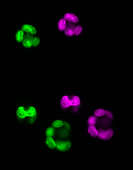

In [ ]:
middle = fixed.images[2].data.shape[0] // 2
whole_fixed, whole_moving = (np.asarray(image.images[2].data[middle]) for image in (fixed, moving))
overlay(whole_fixed, whole_moving, OUTPUT / "before.png")
Image(OUTPUT / "before.png", width=340)

Green is the fixed image, magenta the moving one. The same organoid, but it moved between the two rounds: the two
colours do not overlap at all.

## Or a box

To look closely at one place, take a box of the full-resolution level. Only the chunks it touches are read:

9 chunks read, of the 30 of the full-resolution level


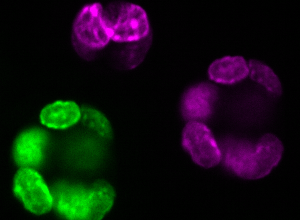

In [ ]:
box = (slice(380, 600), slice(170, 470))  # y and x, in voxels of level 0
middle = fixed.images[0].data.shape[0] // 2
piece = fixed.images[0].data[middle][box]
print(f"{piece.npartitions} chunks read, of the {fixed.images[0].data.npartitions} of the full-resolution level")

overlay(np.asarray(piece), np.asarray(moving.images[0].data[middle][box]), OUTPUT / "box.png")
Image(OUTPUT / "box.png", width=300)

## The same, on a server

`nz.from_ngff_zarr` takes a URL as it takes a folder, and reads it the same way: the metadata first, then the chunks you
touch. The series the [demo](../demo/README.md) registers is a mouse embryo on the IDR, 9.3 TB in all. Opening it, and
reading one box of its coarsest level, costs a moment:

In [ ]:
series = nz.from_ngff_zarr("https://livingobjects.ebi.ac.uk/idr/zarr/v0.4/idr0044A/4007801.zarr")
for level, image in enumerate(series.images):
    print(f"level {level}: {' x '.join(str(extent) for extent in image.data.shape)} ({', '.join(image.dims)})")

coarse = series.images[-1].data
box = coarse[150, 0, coarse.shape[2] // 2, 40:104, 40:104]  # time point 150, channel 0, the middle plane
print(f"one box of {box.shape[0]} x {box.shape[1]} voxels: {box.npartitions} chunk read, mean value {np.asarray(box).mean():.0f}")

level 0: 532 x 2 x 988 x 2048 x 2169 (t, c, z, y, x)
level 1: 532 x 2 x 988 x 1024 x 1084 (t, c, z, y, x)
level 2: 532 x 2 x 988 x 512 x 542 (t, c, z, y, x)
level 3: 532 x 2 x 988 x 256 x 271 (t, c, z, y, x)
level 4: 532 x 2 x 988 x 128 x 135 (t, c, z, y, x)


one box of 64 x 64 voxels: 1 chunk read, mean value 76


**Next: [Step 2. Register](2-register.ipynb)**